In Project 1, we directly accepted request data using Body. In Project 2, we're going to introduce Pydantic to validate incoming data before using it in our application.

Earlier we are implementing POST method without any validation We are not validating the structure or values of the incoming data.

For example, what if someone sends a rating as a string instead of an integer?

{
    "id": 7,
    "title": "HP4",
    "author": "Author Four",
    "description": "Book description",
    "rating": "Excellent"
}

We need a proper validation mechanism.

2. What is Pydantic?
Pydantic

A Python library for data validation, parsing, and serialization.

Official documentation


Pydantic allows us to:
- Define the expected structure of incoming data.
- Validate data types.
- Apply constraints to individual fields.
- Generate meaningful validation errors.
- Convert valid input into structured Python objects.

**How to Create a Pydantic request model**

In [1]:
#First, import BaseModel and Field.

from pydantic import BaseModel, Field

In [2]:
#Now create a separate class called BookRequest.
'''
BaseModel is the parent class provided by Pydantic.
When BookRequest inherits from BaseModel, it gets Pydantic's validation functionality.
'''
class BookRequest(BaseModel):
    id: int
    title: str
    author: str
    description: str
    rating: int


In [ ]:
## Example of creating a BookRequest object with the required fields.
BookRequest(
    id=7,
    title="HP4",
    author="Author Four",
    description="Book description",
    rating=5
)

BookRequest(id=7, title='HP4', author='Author Four', description='Book description', rating=5)

In [ ]:
## Example of creating a BookRequest object with not correct data type 
# for the rating field.
BookRequest(
    id=7,
    title="HP4",
    author="Author Four",
    description="Book description",
    rating='Five'
)

ValidationError: 1 validation error for BookRequest
rating
  Input should be a valid integer, unable to parse string as an integer [type=int_parsing, input_value='Five', input_type=str]
    For further information visit https://errors.pydantic.dev/2.14/v/int_parsing

In [5]:
'''4. What is Field()?
It allows us to define additional validation rules and metadata for individual fields.
'''

class BookRequest(BaseModel):
    id: int
    title: str = Field(min_length=3)
    author: str = Field(min_length=3)
    description: str = Field(min_length=5)
    rating: int = Field(gt=0, lt=6)

Here is what the constraints mean:
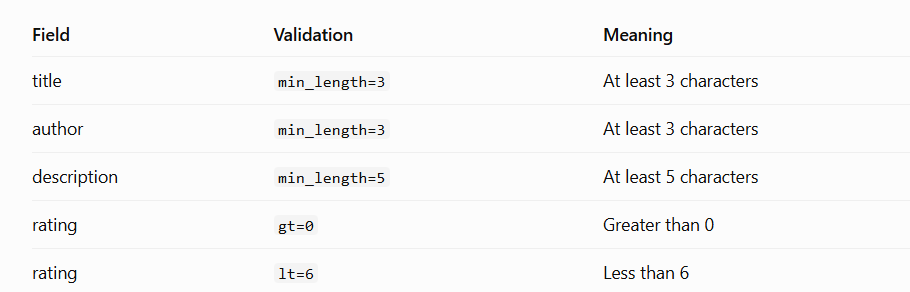

**Why do we need two classes: Book and BookRequest?**

We have two different classes:
1. `Book`: Represents the actual book object that our application stores and works with.
2. `BookRequest`: This class is used for validating incoming POST requests. 
It ensures that the data provided by the client meets the required criteria 
before it's processed further.

By separating these concerns, we can maintain clean and well-defined APIs while
 ensuring data integrity.

In [6]:
class Book:
    def __init__(self, id, title, author,
                 description, rating):
        self.id = id
        self.title = title
        self.author = author
        self.description = description
        self.rating = rating

Think of it this way:
- BookRequest → Is the incoming data valid?
- Book → Create the actual Python object that our application will store.

This separation is useful because API input validation and internal application representation are two different responsibilities.

In [ ]:
#Convert BookRequest into a Book object

@app.post("/create_book")
async def create_book(book_request: BookRequest):

    new_book = Book(**book_request.dict())

    books.append(new_book)

**Let's understand this step by step.**

- Step 1: Receive the request
    book_request: BookRequest

    FastAPI recognizes the Pydantic model and automatically:
    1. Reads the JSON request body.
    2. Validates it using BookRequest.
    3. Creates a BookRequest instance.
    4. Returns a validation error if the input is invalid.
    You don't need to explicitly use Body() here. FastAPI infers the request body from the  Pydantic model.


- Step 2: Convert the Pydantic model into a dictionary
    book_request.dict()


    Suppose the incoming request is:
    {
        "id": 7,
        "title": "HP4",
        "author": "Author Four",
        "description": "Book description",
        "rating": 5
    }


    The dictionary representation is:
    {    "id": 7,    "title": "HP4",    "author": "Author Four",    "description": "Book       description",    "rating": 5}
    
**Note: In Pydantic V2, prefer model_dump() instead of .dict() because .dict() is deprecated.**

- Step 3: Understand **

    Consider:
    data = {    "id": 7,    "title": "HP4",    "author": "Author Four",    "description":   "Book description",    "rating": 5}



    When we write:
    new_book = Book(**data)



    Python automatically unpacks the dictionary into keyword arguments.

    It is equivalent to:
    new_book = Book(    id=7,    title="HP4",    author="Author Four",      description="Book description",    rating=5)



    That's how we convert the Pydantic request into our regular Python Book object.

Example by running the code 

I have put string in rating in POST 

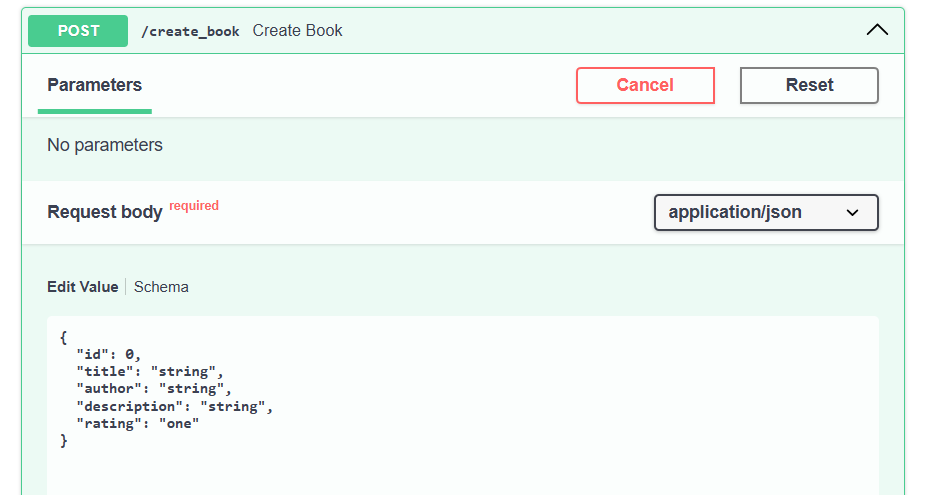

The response 

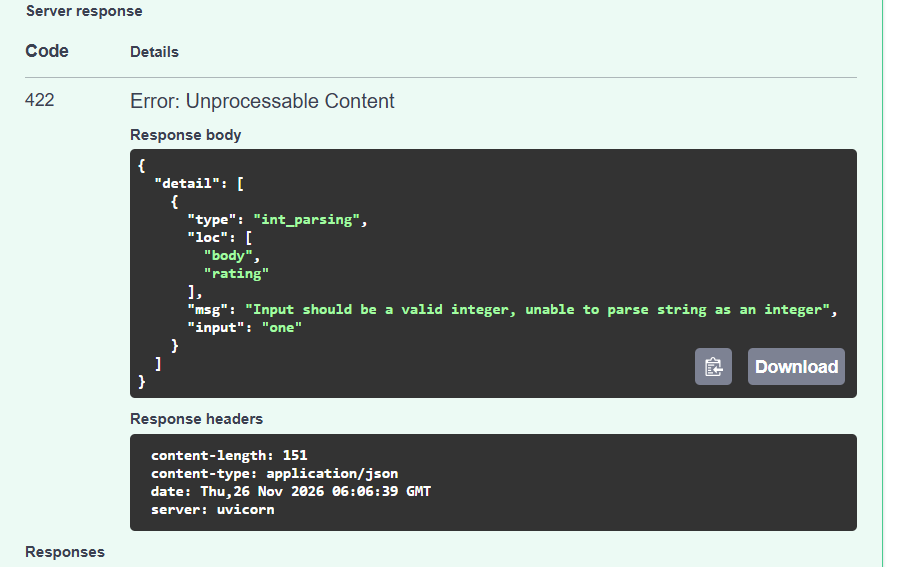